# Ejemplo Celtis Tala, fruto
---

## Variables (mediciones)

* **diam**: diámetro
* **az**: concentración de azúcar
* **pulpa**: peso
* **sem**: peso
* **pulpa.sem**: relación peso de la pulpa - peso de la semilla

In [1]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
df = pd.read_table('/Users/ppando/Materias/cs-datos/especializacion/data/Celtis.txt')
df.head()

,diam,az,pulpa,sem,pulpa.sem
0,9.257,18.5,0.361,0.0523,6.911
1,8.125,21.5,0.252,0.0393,6.408
2,9.011,18.5,0.331,0.0556,5.962
3,8.568,23.5,0.287,0.0519,5.534
4,7.484,16.5,0.177,0.0443,4.004


## Matriz de correlación

In [3]:
df.corr()

,diam,az,pulpa,sem,pulpa.sem
diam,1.000000,-0.329938,0.993143,0.449712,0.559886
az,-0.329938,1.000000,-0.373178,0.199536,-0.494100
pulpa,0.993143,-0.373178,1.000000,0.342252,0.645232
sem,0.449712,0.199536,0.342252,1.000000,-0.430054
pulpa.sem,0.559886,-0.494100,0.645232,-0.430054,1.000000


* En R: round(corr(Celtis), 3)
* se observa fuerte correlación entre **diam** y **pulpa** y la **pulpa** con **pulpa.sem**

## PCA

In [4]:
# Estandarizar
scaler = StandardScaler()
Xscaled = scaler.fit_transform(df)

In [5]:
# Aplicar PCA
pca = PCA(n_components=5)
Xpca = pca.fit_transform(Xscaled)

* En R: PCA(Celtis, scale.unit=TRUE) de la libreria FactoMineR

## Autovalores

In [6]:
# Autovalores
eigenvalues = pca.explained_variance_
eigenvalues_df = pd.DataFrame(eigenvalues, columns=['Autovalores'], index=['PC1', 'PC2', 'PC3', 'PC4', 'PC5'])
eigenvalues_df

,Autovalores
PC1,2.769406
PC2,1.579522
PC3,0.610292
PC4,0.048932
PC5,0.000005


In [7]:
eigenvalues_df.sum()

Autovalores    5.008157
dtype: float64

* **Autovalores**: dan cuanta varianza explica cada componente. La suma de los autovalores tiene que dar p (en este caso 5)

## % varianza explicada

In [8]:
# Porcentaje de varianza explicada
explained_variance_ratio = pca.explained_variance_ratio_ * 100
explained_variance_ratio_df = pd.DataFrame(explained_variance_ratio, columns=['% Varianza explicada'], 
                                           index=['PC1', 'PC2', 'PC3', 'PC4', 'PC5'])
explained_variance_ratio_df

,% Varianza explicada
PC1,55.297911
PC2,31.538989
PC3,12.185953
PC4,0.977049
PC5,0.000098


In [9]:
explained_variance_ratio_df.sum()

% Varianza explicada    100.0
dtype: float64

* **% varianza explicada**: autovalor / p (en este caso 2.77 / 5 * 100 = 55.30).
* La suma tiene que dar 100
* Siempre decrece
* El comp 1 explica el mayor porcentaje (en este caso 55.30)

## Varianza acumulada

In [10]:
# Varianza acumulada
cumulative_variance = np.cumsum(explained_variance_ratio)
cumulative_variance_df = pd.DataFrame(cumulative_variance, columns=['Varianza acumulada'], index=['PC1', 'PC2', 'PC3', 'PC4', 'PC5'])
cumulative_variance_df

,Varianza acumulada
PC1,55.297911
PC2,86.836900
PC3,99.022853
PC4,99.999902
PC5,100.000000


* Si se acumula, se dice que las dos primeras componentes principales explican el 86.84%) => ambas retienen la mayor cantidad de información de los datos
* La varianza se mide como cantidad de información

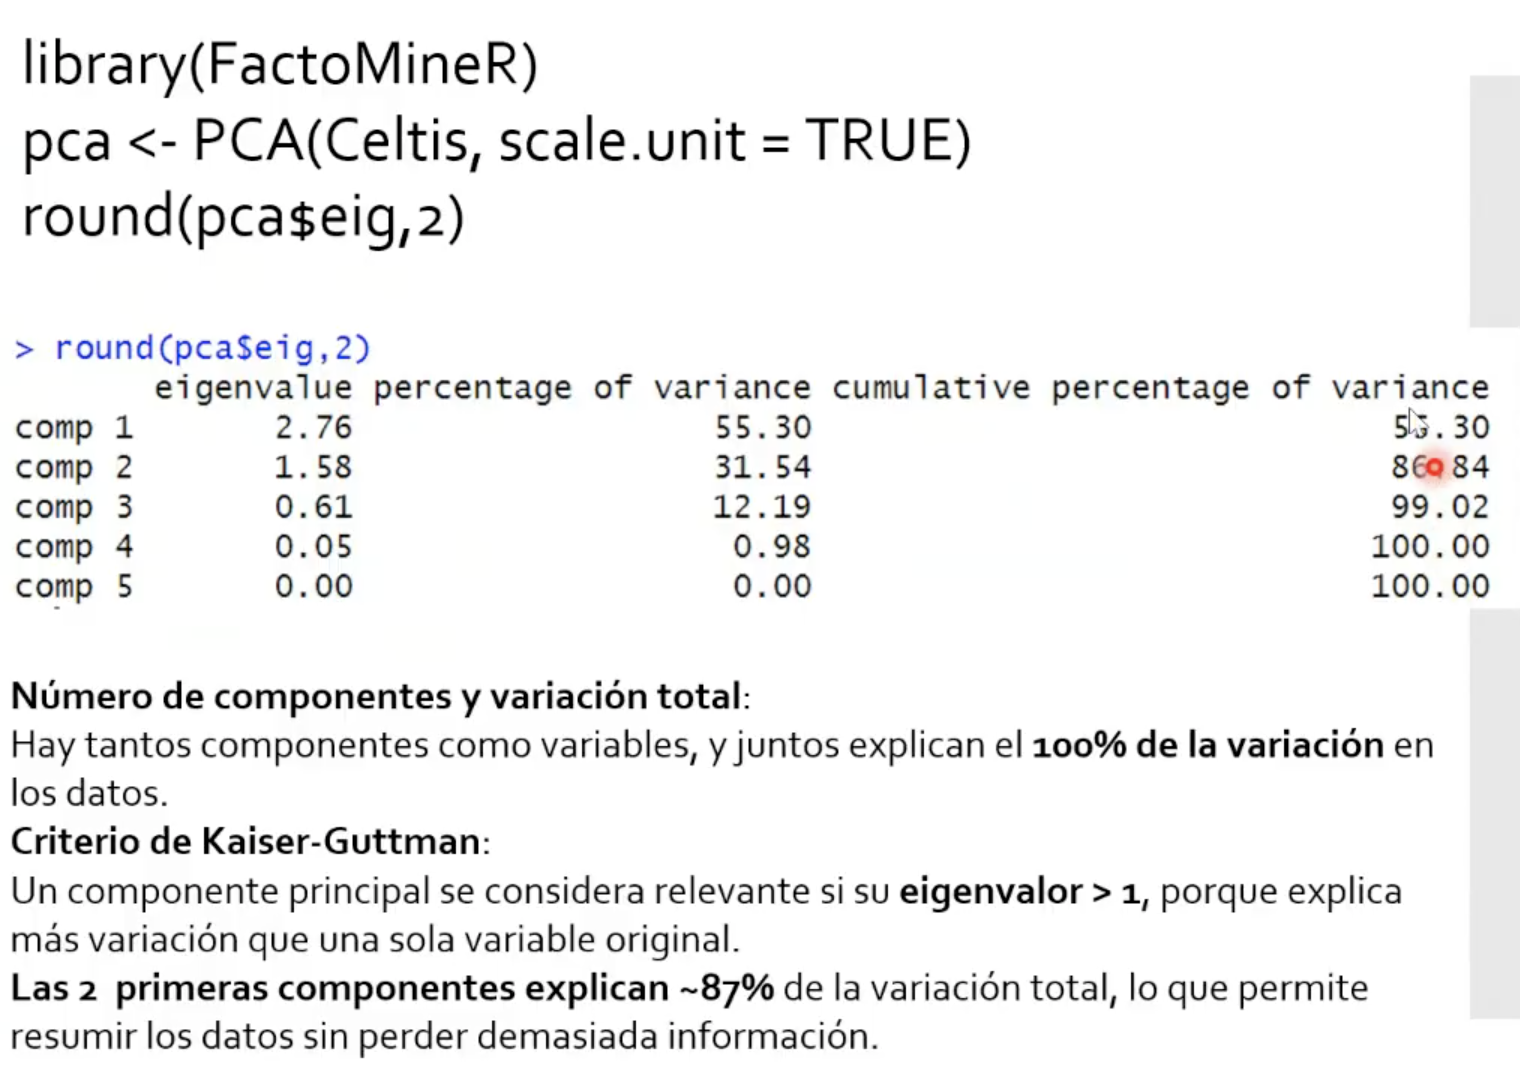

## Gráfico de sedimentación (scree plot)

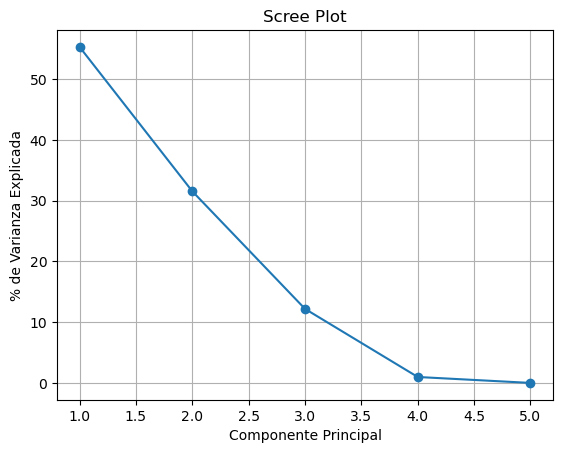

In [11]:
# Scree Plot
plt.plot(range(1, len(eigenvalues)+1), explained_variance_ratio, marker='o')
plt.title('Scree Plot')
plt.xlabel('Componente Principal')
plt.ylabel('% de Varianza Explicada')
plt.grid(True)
plt.show()

* El punto donde se produce una estabilización de la varianza explicada ("codo") indica el número de componentes que se deben retener
* Los valores de la varianza explicada no cambian demasiado del PC4 al PC5, por lo que utilizando cuatro componentes seria suficiente para su interpretación.
* Este criterio arroja un número irracionalmente alto de componentes

## Autovectores

In [12]:
# Autovectores
eigenvectors = pca.components_
eigenvectors_df = pd.DataFrame(eigenvectors, columns=['PC1', 'PC2', 'PC3', 'PC4', 'PC5'], index=df.columns)
eigenvectors_df

,PC1,PC2,PC3,PC4,PC5
diam,0.564570,-0.345920,0.580235,0.104546,0.462599
az,0.261207,0.370620,0.175510,0.758862,-0.433286
pulpa,0.108827,0.861804,0.150257,-0.273326,0.384924
sem,-0.282815,-0.016578,-0.373150,0.574806,0.670894
pulpa.sem,0.721945,0.000016,-0.686080,-0.089944,-0.000199


* **Autovectores**: con ellos se obtienen las cargas (loadings)

## Loadings

In [13]:
loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
loadings_df = pd.DataFrame(loadings, columns=['PC1', 'PC2', 'PC3', 'PC4', 'PC5'], index=df.columns)
loadings_df

,PC1,PC2,PC3,PC4,PC5
diam,0.939531,0.328282,0.085017,-0.062560,1.601012e-03
az,-0.575665,0.465791,0.673251,-0.003667,3.506836e-08
pulpa,0.965599,0.220579,0.117383,-0.082543,-1.521477e-03
sem,0.173981,0.953730,-0.213526,0.127151,-1.994630e-04
pulpa.sem,0.769836,-0.544550,0.300707,0.148406,-4.411808e-07


* **Loadings**: coeficientes de correlación entre una variable y su respectivo componente principal
* El PC1 tiene una asociación fuerte y positiva con el diámetro, el peso de la pulpa y la relación peso de la pulpa-peso de la semilla
* y en menor medida, una asociación negativa con la concentración de azúcar. Esto es consistente con el análisis de la matriz de correlación
* Dan los coeficientes que después van a hacer las cargas

$$CP1 = 0.939 * diam - 0.575 * az + 0.965 * pulpa + 0.173 * sem + 0.769 * pulpa.sem$$
$$CP2 = 0.328 * diam + 0.465 * az + 0.220 * pulpa + 0.953 * sem - 0.544 * pulpa.sem$$

* En R, las Dim son las componentes principales
* **Score o puntuaciones**: es el valor que le corresponde al punto en el nuevo subespacio

## $cos^2$

In [14]:
# cos²: cuadrado de las correlaciones entre variables y componentes
cos2 = (eigenvectors**2) * eigenvalues[:, np.newaxis]
cos2_df = pd.DataFrame(cos2.T, index=df.columns, columns=[f"PC{i+1}" for i in range(5)])
cos2_df

,PC1,PC2,PC3,PC4,PC5
diam,0.882718,0.107769,0.007228,0.003914,2.563238e-06
az,0.331390,0.216961,0.453267,0.000013,1.229790e-15
pulpa,0.932382,0.048655,0.013779,0.006813,2.314892e-06
sem,0.030269,0.909601,0.045593,0.016167,3.978549e-08
pulpa.sem,0.592647,0.296535,0.090425,0.022024,1.946405e-13


In [15]:
cos2_df['PC1'].sum()

2.7694059686971007

* Tabla de cos2, que dice "cuanto aporta cada variable a cada dimensión"
* Si se suman los cos2 se obtiene el valor de los autovalores, que estan relacionados con el % de varianza explicada

## Contribución

In [16]:
# Contribución de cada variable a cada componente (en %)
contrib = (cos2.T * pca.explained_variance_ratio_ * 100).T
contrib_df = pd.DataFrame(contrib.T, index=df.columns, columns=[f"PC{i+1}" for i in range(5)])
contrib_df

,PC1,PC2,PC3,PC4,PC5
diam,48.812450,3.398933,0.088079,0.003824,2.517052e-10
az,18.325154,6.842744,5.523488,0.000013,1.207631e-19
pulpa,51.558761,1.534537,0.167906,0.006657,2.273181e-10
sem,1.673839,28.687906,0.555597,0.015796,3.906861e-12
pulpa.sem,32.772160,9.352406,1.101914,0.021519,1.911334e-17


In [17]:
contrib_df['PC1'].sum()

153.14236397804524

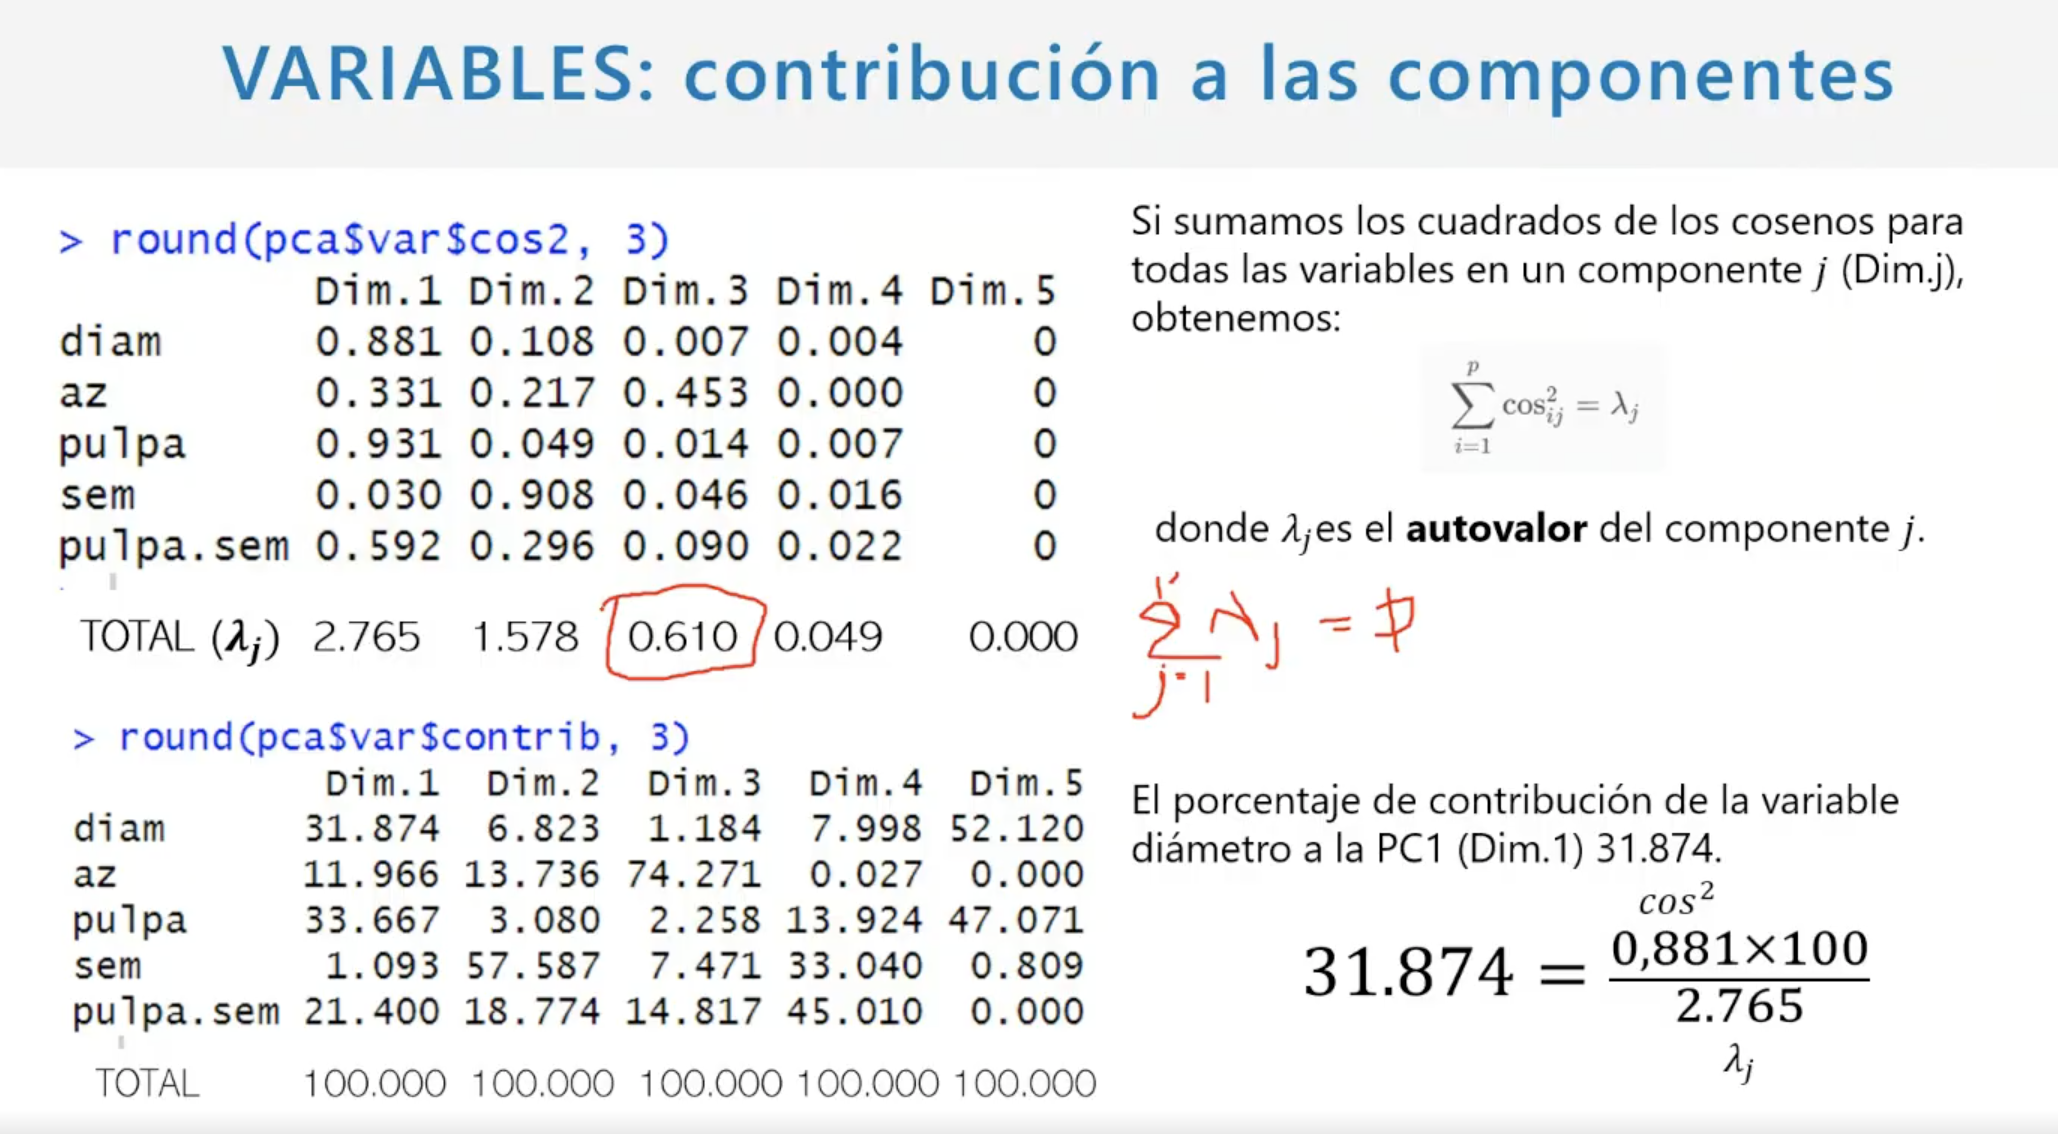

## Circulo de correlación

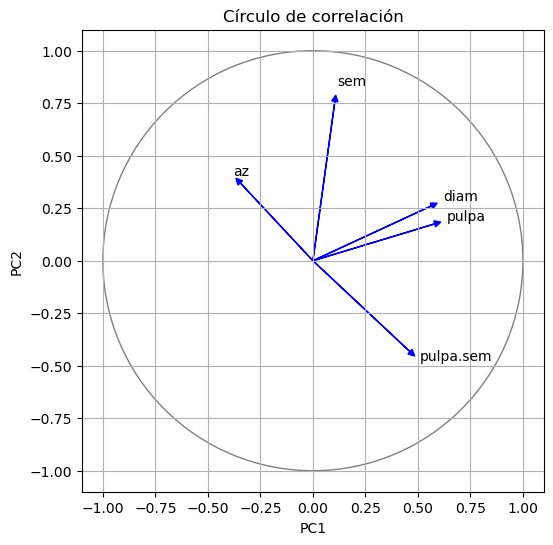

In [18]:
# Círculo de correlación
plt.figure(figsize=(6,6))
for i, var in enumerate(df.columns):
    plt.arrow(0, 0, eigenvectors[0, i], eigenvectors[1, i],
              head_width=0.03, head_length=0.03, fc='blue', ec='blue')
    plt.text(eigenvectors[0, i]*1.1, eigenvectors[1, i]*1.1, var, color='black')

circle = plt.Circle((0, 0), 1, color='gray', fill=False)
plt.gca().add_artist(circle)
plt.xlim(-1.1, 1.1)
plt.ylim(-1.1, 1.1)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Círculo de correlación")
plt.grid()
plt.gca().set_aspect('equal', adjustable='box')
plt.show()

* Se llevan todas las variables a un círculo que tiene radio 1
* Cuando las variables están más cerca de la circunferencia, tienen mayor contribución a las componentes
* Cuando forman un ángulo muy chico entre las variables (diam y pulpa) significa que están muy relacionadas
* Cuando estan diametralmente opuestas (pulpa.sem y az) significa que son muy distintas

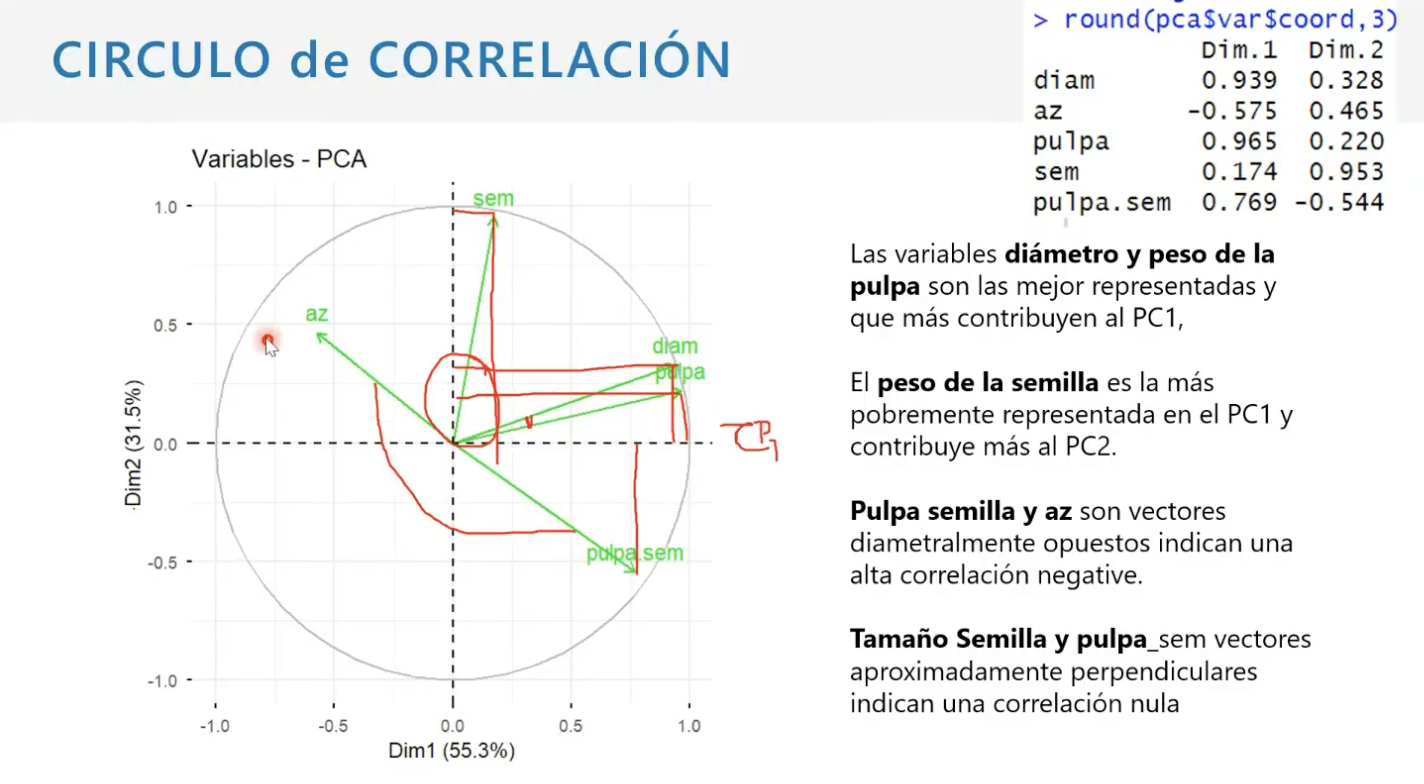

## Biplot PC1 y PC2

In [19]:
len(df)

614

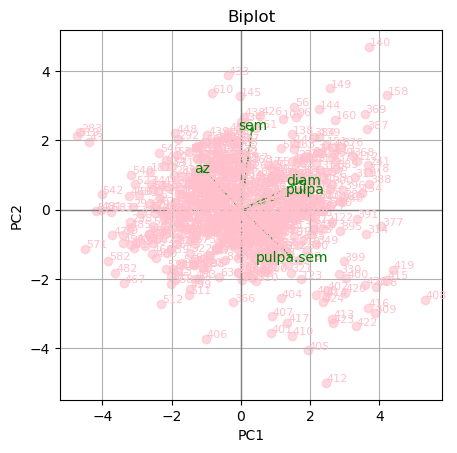

In [20]:
#Individuos+variables

# Crear biplot con colores por especie
#plt.figure(figsize=(8, 6))

for idx in range(len(df)):
    x, y = Xpca[idx, 0], Xpca[idx, 1]
    plt.scatter(x, y, alpha=0.6, color='pink')
    plt.text(x + 0.02, y + 0.02, idx, fontsize=8, color='pink')

# Graficar vectores de variables
variables = df.columns
for i in range(len(variables)):
    plt.arrow(0, 0, eigenvectors[0, i]*3, eigenvectors[1, i]*3,
              color='green', alpha=0.7, head_width=0.1)
    plt.text(eigenvectors[0, i]*3.2, eigenvectors[1, i]*3.2,
             variables[i], color='green', ha='center', va='center')

# Configurar gráfico
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Biplot")
plt.grid()
plt.axhline(0, color='gray', lw=1)
plt.axvline(0, color='gray', lw=1)
plt.gca().set_aspect('equal', adjustable='box')
plt.show()

*  Se mezclan individuos (UE unidades experimentales) con variables
*  Se observa como  se correlacionan las variables y como se ubican los individuos

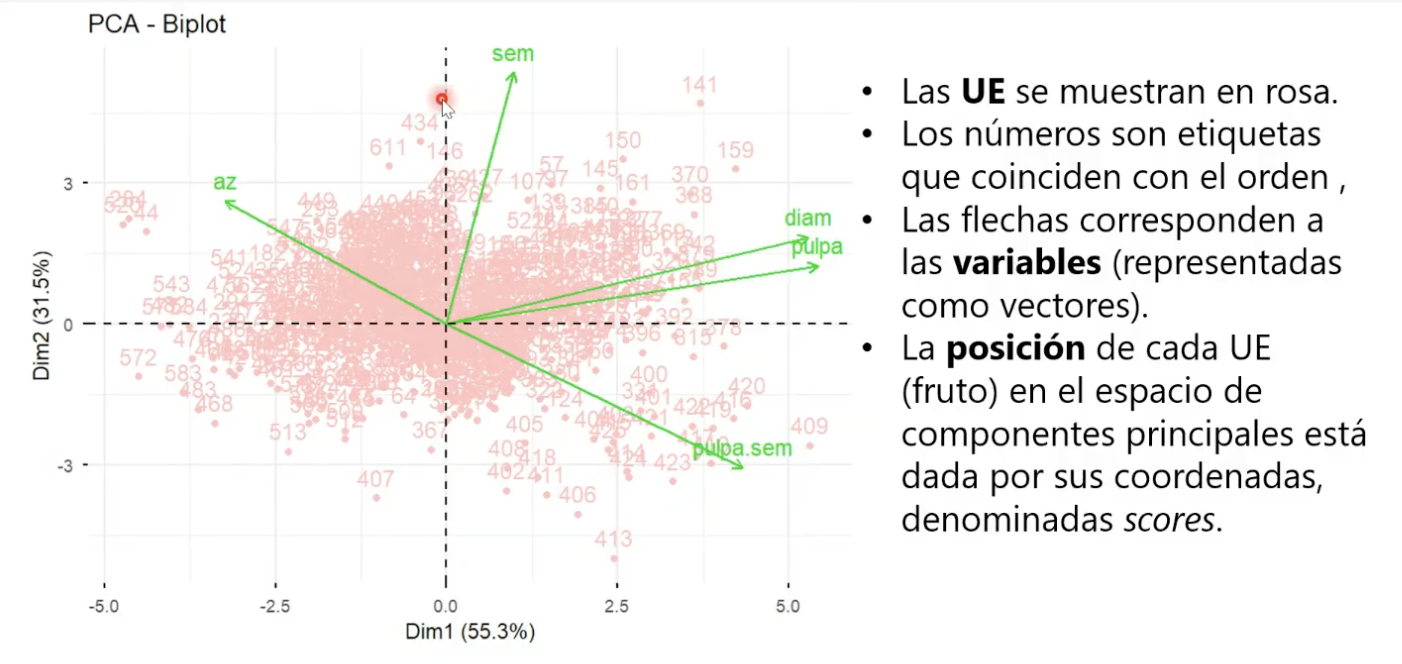

1. Las UE cercanas en el espacio tienen caracteristicas similares en cuanto a sus variables
2. El coseno del ángulo entre dos vectores corresponde a su correlación. Por lo tanto, vectores cercanos indican una alta correlación positiva, vectores diametralmente opuestos indican una alta correlación negativa, y vectores perpendiculares indican una correlación nula
3. El coseno del ángulo entre un vector y una componente principal corresponde a su correlación
4. Una UE en la dirección y sentido de una variable y alejada del centro de origen tiene un valor alto para esa variable

* **El diámetro del fruto** y el **peso de la pulpa** se encuentran muy correlacionados entre sí y de forma positiva, mientras que
ambos se encuentran levemente correlacionados y de forma negativa con la concentración de **azúcar**
* Son las variables que se encuentran más correlacionadas con el PC1 y también las que más contribuyen a este componente,
* El **peso de la semilla** se encuentra casi paralelo al PC2, y es también la que más contribuye a este último

* En la flecha de **sem** están los frutos con semillas grandes
* Opuesto los frutos con semillas pequeñas
* En la flecha de **diam** y **pulpa**, frutos de gran tamaño y bajo contenido de azucar (porque está opuesto al azúcar)
* En la flecha de **az**, frutos pequeños y con alto contenido de azúcar